In [1]:
# ============================================================
# Future Market Value Prediction - Imports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# Load Temporal ML Dataset
# ============================================================

DATA_PATH = '../../../data/processed/temporal_market_value_dataset.csv'

df = pd.read_csv(
    DATA_PATH,
    parse_dates=[
        'snapshot_date',
        'target_date',
        'future_date',
        'performance_window_start'
    ]
)

print("=" * 70)
print("TEMPORAL ML DATASET LOADED")
print("=" * 70)

print(f"Rows    : {len(df):,}")
print(f"Columns : {df.shape[1]}")
print(f"Players : {df['player_id'].nunique():,}")

print("\nSnapshot date range:")
print(
    df['snapshot_date'].min(),
    "→",
    df['snapshot_date'].max()
)

print("\nFuture target date range:")
print(
    df['future_date'].min(),
    "→",
    df['future_date'].max()
)

print("\nFirst 5 rows:")
display(df.head())

TEMPORAL ML DATASET LOADED
Rows    : 213,905
Columns : 26
Players : 24,275

Snapshot date range:
2012-07-06 00:00:00 → 2025-12-22 00:00:00

Future target date range:
2012-12-29 00:00:00 → 2026-05-18 00:00:00

First 5 rows:


,player_id,snapshot_date,target_date,future_date,target_distance_days,performance_window_start,current_market_value,age_at_snapshot,games_last_6m,goals_last_6m,assists_last_6m,minutes_last_6m,yellow_cards_last_6m,red_cards_last_6m,goals_per_90_last_6m,assists_per_90_last_6m,goal_contribution_per_90_last_6m,minutes_per_game_last_6m,height_in_cm,position,sub_position,foot,country_of_citizenship,future_market_value,future_value_change_eur,future_value_change_pct
0,4520,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,2500000,32.63,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,181.00,Defender,Centre-Back,right,Netherlands,2000000,-500000,-20.00
1,30003,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,5000000,25.88,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,176.00,Midfield,Defensive Midfield,right,NaN,4500000,-500000,-10.00
2,47740,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,400000,20.40,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,190.00,Defender,Centre-Back,both,Germany,600000,200000,50.00
3,60312,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,600000,23.76,1.00,1.00,1.00,45.00,0.00,0.00,NaN,NaN,NaN,45.00,175.00,Attack,Left Winger,right,Aruba,1250000,650000,108.33
4,80073,2012-07-06,2013-01-06,2013-01-09,3,2012-01-06,1500000,25.43,1.00,2.00,1.00,90.00,0.00,0.00,2.00,1.00,3.00,90.00,194.00,Attack,Centre-Forward,right,Netherlands,2000000,500000,33.33


In [3]:
# ============================================================
# Define Features and Target
# ============================================================

NUMERIC_FEATURES = [
    'current_market_value',
    'age_at_snapshot',
    'games_last_6m',
    'goals_last_6m',
    'assists_last_6m',
    'minutes_last_6m',
    'yellow_cards_last_6m',
    'red_cards_last_6m',
    'goals_per_90_last_6m',
    'assists_per_90_last_6m',
    'goal_contribution_per_90_last_6m',
    'minutes_per_game_last_6m',
    'height_in_cm'
]

CATEGORICAL_FEATURES = [
    'position',
    'sub_position',
    'foot',
    'country_of_citizenship'
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

TARGET = 'future_market_value'

print("=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print(f"Numeric features     : {len(NUMERIC_FEATURES)}")
print(f"Categorical features : {len(CATEGORICAL_FEATURES)}")
print(f"Total features       : {len(FEATURES)}")

print("\nTarget:")
print(f"  {TARGET}")

print("\nPredictive features:")
for feature in FEATURES:
    print(f"  - {feature}")

print("\nTarget leakage check:")
for forbidden in [
    'future_market_value',
    'future_value_change_eur',
    'future_value_change_pct',
    'future_date',
    'target_date'
]:
    print(
        f"  {forbidden:<25} "
        f"in FEATURES = {forbidden in FEATURES}"
    )

FEATURES AND TARGET
Numeric features     : 13
Categorical features : 4
Total features       : 17

Target:
  future_market_value

Predictive features:
  - current_market_value
  - age_at_snapshot
  - games_last_6m
  - goals_last_6m
  - assists_last_6m
  - minutes_last_6m
  - yellow_cards_last_6m
  - red_cards_last_6m
  - goals_per_90_last_6m
  - assists_per_90_last_6m
  - goal_contribution_per_90_last_6m
  - minutes_per_game_last_6m
  - height_in_cm
  - position
  - sub_position
  - foot
  - country_of_citizenship

Target leakage check:
  future_market_value       in FEATURES = False
  future_value_change_eur   in FEATURES = False
  future_value_change_pct   in FEATURES = False
  future_date               in FEATURES = False
  target_date               in FEATURES = False


In [4]:
# ============================================================
# Investigate Temporal Split
# ============================================================

df['snapshot_year'] = df['snapshot_date'].dt.year

year_distribution = (
    df.groupby('snapshot_year')
      .agg(
          Snapshots=('player_id', 'size'),
          Players=('player_id', 'nunique')
      )
      .reset_index()
)

year_distribution['Percent'] = (
    year_distribution['Snapshots']
    / len(df)
    * 100
)

print("=" * 70)
print("SNAPSHOT DISTRIBUTION BY YEAR")
print("=" * 70)

display(year_distribution)

print("\nTotal snapshots:")
print(f"{len(df):,}")

SNAPSHOT DISTRIBUTION BY YEAR


,snapshot_year,Snapshots,Players,Percent
0,2012,797,783,0.37
1,2013,7320,4463,3.42
2,2014,10766,6196,5.03
3,2015,11341,7084,5.30
4,2016,16007,8699,7.48
5,2017,14925,8991,6.98
6,2018,18596,10096,8.69
7,2019,16482,10426,7.71
8,2020,19030,10762,8.90
9,2021,24930,12322,11.65



Total snapshots:
213,905


In [5]:
# ============================================================
# Temporal Train / Validation / Test Split
# ============================================================

TRAIN_END = pd.Timestamp('2023-12-31')
VALIDATION_START = pd.Timestamp('2024-01-01')
VALIDATION_END = pd.Timestamp('2024-12-31')
TEST_START = pd.Timestamp('2025-01-01')

# ------------------------------------------------------------
# Training:
# Snapshot is before 2024 AND its future target is also
# observed before validation begins.
# ------------------------------------------------------------

train_df = df[
    (df['snapshot_date'] <= TRAIN_END) &
    (df['future_date'] < VALIDATION_START)
].copy()

# ------------------------------------------------------------
# Validation:
# Snapshot occurs during 2024 AND its future target is
# observed before the test period begins.
# ------------------------------------------------------------

validation_df = df[
    (df['snapshot_date'] >= VALIDATION_START) &
    (df['snapshot_date'] <= VALIDATION_END) &
    (df['future_date'] < TEST_START)
].copy()

# ------------------------------------------------------------
# Test:
# Snapshot occurs from 2025 onward.
# ------------------------------------------------------------

test_df = df[
    df['snapshot_date'] >= TEST_START
].copy()

print("=" * 70)
print("TEMPORAL TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

print(f"Training rows   : {len(train_df):,}")
print(f"Validation rows : {len(validation_df):,}")
print(f"Test rows       : {len(test_df):,}")

print("\nSnapshot ranges:")

print(
    "Train      :",
    train_df['snapshot_date'].min(),
    "→",
    train_df['snapshot_date'].max()
)

print(
    "Validation :",
    validation_df['snapshot_date'].min(),
    "→",
    validation_df['snapshot_date'].max()
)

print(
    "Test       :",
    test_df['snapshot_date'].min(),
    "→",
    test_df['snapshot_date'].max()
)

print("\nFuture target ranges:")

print(
    "Train      :",
    train_df['future_date'].min(),
    "→",
    train_df['future_date'].max()
)

print(
    "Validation :",
    validation_df['future_date'].min(),
    "→",
    validation_df['future_date'].max()
)

print(
    "Test       :",
    test_df['future_date'].min(),
    "→",
    test_df['future_date'].max()
)

TEMPORAL TRAIN / VALIDATION / TEST SPLIT
Training rows   : 174,997
Validation rows : 8,200
Test rows       : 10,892

Snapshot ranges:
Train      : 2012-07-06 00:00:00 → 2023-08-03 00:00:00
Validation : 2024-01-03 00:00:00 → 2024-07-19 00:00:00
Test       : 2025-01-01 00:00:00 → 2025-12-22 00:00:00

Future target ranges:
Train      : 2012-12-29 00:00:00 → 2023-12-30 00:00:00
Validation : 2024-05-28 00:00:00 → 2024-12-30 00:00:00
Test       : 2025-05-28 00:00:00 → 2026-05-18 00:00:00


In [6]:
# ============================================================
# Temporal Split Validation
# ============================================================

train_target_safe = (
    train_df['future_date'] < VALIDATION_START
).all()

validation_snapshot_safe = (
    validation_df['snapshot_date'] >= VALIDATION_START
).all()

validation_target_safe = (
    validation_df['future_date'] < TEST_START
).all()

test_snapshot_safe = (
    test_df['snapshot_date'] >= TEST_START
).all()

print("=" * 70)
print("TEMPORAL SPLIT VALIDATION")
print("=" * 70)

print(
    f"All training targets before validation : "
    f"{train_target_safe}"
)

print(
    f"All validation snapshots in 2024       : "
    f"{validation_snapshot_safe}"
)

print(
    f"All validation targets before test     : "
    f"{validation_target_safe}"
)

print(
    f"All test snapshots from 2025 onward    : "
    f"{test_snapshot_safe}"
)

print("\nRows:")
print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(validation_df):,}")
print(f"Test       : {len(test_df):,}")

all_checks_passed = all([
    train_target_safe,
    validation_snapshot_safe,
    validation_target_safe,
    test_snapshot_safe
])

print("\n" + "=" * 70)
print(f"ALL TEMPORAL CHECKS PASSED: {all_checks_passed}")
print("=" * 70)

TEMPORAL SPLIT VALIDATION
All training targets before validation : True
All validation snapshots in 2024       : True
All validation targets before test     : True
All test snapshots from 2025 onward    : True

Rows:
Train      : 174,997
Validation : 8,200
Test       : 10,892

ALL TEMPORAL CHECKS PASSED: True


In [7]:
# ============================================================
# Prepare X and y for Temporal Modelling
# ============================================================

# Predictor columns already defined earlier
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = 'future_market_value'

# ------------------------------------------------------------
# Training set
# ------------------------------------------------------------

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

# ------------------------------------------------------------
# Validation set
# ------------------------------------------------------------

X_validation = validation_df[FEATURES].copy()
y_validation = validation_df[TARGET].copy()

# ------------------------------------------------------------
# Test set
# ------------------------------------------------------------

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("=" * 70)
print("TEMPORAL MODELLING DATA")
print("=" * 70)

print("\nFeature matrices:")
print(f"X_train      : {X_train.shape}")
print(f"X_validation : {X_validation.shape}")
print(f"X_test       : {X_test.shape}")

print("\nTarget vectors:")
print(f"y_train      : {y_train.shape}")
print(f"y_validation : {y_validation.shape}")
print(f"y_test       : {y_test.shape}")

print("\nNumber of predictive features:")
print(len(FEATURES))

print("\nTarget:")
print(TARGET)

# Safety checks
assert X_train.shape[1] == len(FEATURES)
assert X_validation.shape[1] == len(FEATURES)
assert X_test.shape[1] == len(FEATURES)

assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

print("\nX / y validation passed.")

TEMPORAL MODELLING DATA

Feature matrices:
X_train      : (174997, 17)
X_validation : (8200, 17)
X_test       : (10892, 17)

Target vectors:
y_train      : (174997,)
y_validation : (8200,)
y_test       : (10892,)

Number of predictive features:
17

Target:
future_market_value

X / y validation passed.


In [8]:
# ============================================================
# Preprocessing Pipeline
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


# ------------------------------------------------------------
# Numeric preprocessing
# ------------------------------------------------------------

numeric_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(strategy='median')
        )
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(strategy='most_frequent')
        ),
        (
            'onehot',
            OneHotEncoder(
                handle_unknown='ignore'
            )
        )
    ]
)


# ------------------------------------------------------------
# Combine numeric + categorical preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            numeric_transformer,
            NUMERIC_FEATURES
        ),
        (
            'categorical',
            categorical_transformer,
            CATEGORICAL_FEATURES
        )
    ]
)


print("=" * 70)
print("PREPROCESSING PIPELINE CREATED")
print("=" * 70)

print(f"Numeric features     : {len(NUMERIC_FEATURES)}")
print(f"Categorical features : {len(CATEGORICAL_FEATURES)}")

print("\nNumeric pipeline:")
print("Missing values → Median imputation")

print("\nCategorical pipeline:")
print("Missing values → Most frequent category → OneHotEncoder")

print("\nPreprocessor created successfully.")

PREPROCESSING PIPELINE CREATED
Numeric features     : 13
Categorical features : 4

Numeric pipeline:
Missing values → Median imputation

Categorical pipeline:
Missing values → Most frequent category → OneHotEncoder

Preprocessor created successfully.


In [9]:
# ============================================================
# Naive Persistence Baseline
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# Baseline assumption:
# Future market value = Current market value
# ------------------------------------------------------------

baseline_val_pred = X_validation['current_market_value'].values
baseline_test_pred = X_test['current_market_value'].values


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_regression(y_true, y_pred):

    r2 = r2_score(y_true, y_pred)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    return r2, mae, rmse


# ------------------------------------------------------------
# Validation performance
# ------------------------------------------------------------

baseline_val_r2, baseline_val_mae, baseline_val_rmse = (
    evaluate_regression(
        y_validation,
        baseline_val_pred
    )
)


# ------------------------------------------------------------
# Test performance
# ------------------------------------------------------------

baseline_test_r2, baseline_test_mae, baseline_test_rmse = (
    evaluate_regression(
        y_test,
        baseline_test_pred
    )
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("NAIVE PERSISTENCE BASELINE")
print("=" * 70)

print("""
Baseline assumption:
Future market value ≈ Current market value
""")

print("VALIDATION")
print(f"R²   : {baseline_val_r2:.4f}")
print(f"MAE  : €{baseline_val_mae:,.0f}")
print(f"RMSE : €{baseline_val_rmse:,.0f}")

print("\nTEST")
print(f"R²   : {baseline_test_r2:.4f}")
print(f"MAE  : €{baseline_test_mae:,.0f}")
print(f"RMSE : €{baseline_test_rmse:,.0f}")

NAIVE PERSISTENCE BASELINE

Baseline assumption:
Future market value ≈ Current market value

VALIDATION
R²   : 0.9283
MAE  : €1,201,618
RMSE : €3,357,931

TEST
R²   : 0.9040
MAE  : €1,473,426
RMSE : €3,848,526


In [10]:
# ============================================================
# Linear Regression - Temporal Forecasting
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# ------------------------------------------------------------
# 1. Create Linear Regression pipeline
# ------------------------------------------------------------

linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])


# ------------------------------------------------------------
# 2. Train model using TRAINING data only
# ------------------------------------------------------------

linear_model.fit(X_train, y_train)


# ------------------------------------------------------------
# 3. Predict VALIDATION data
# ------------------------------------------------------------

y_val_pred_linear = linear_model.predict(X_validation)


# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

linear_val_r2 = r2_score(
    y_validation,
    y_val_pred_linear
)

linear_val_mae = mean_absolute_error(
    y_validation,
    y_val_pred_linear
)

linear_val_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_val_pred_linear
    )
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("=" * 70)
print("LINEAR REGRESSION — VALIDATION RESULTS")
print("=" * 70)

print(f"Training rows   : {len(X_train):,}")
print(f"Validation rows : {len(X_validation):,}")

print("\nVALIDATION")
print(f"R²   : {linear_val_r2:.4f}")
print(f"MAE  : €{linear_val_mae:,.0f}")
print(f"RMSE : €{linear_val_rmse:,.0f}")

LINEAR REGRESSION — VALIDATION RESULTS
Training rows   : 174,997
Validation rows : 8,200

VALIDATION
R²   : 0.9280
MAE  : €1,297,271
RMSE : €3,364,479


In [11]:
# ============================================================
# Random Forest - Temporal Forecasting
# ============================================================

from sklearn.ensemble import RandomForestRegressor


# ------------------------------------------------------------
# 1. Create Random Forest pipeline
# ------------------------------------------------------------

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])


# ------------------------------------------------------------
# 2. Train using TRAINING data only
# ------------------------------------------------------------

random_forest_model.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 3. Predict VALIDATION data
# ------------------------------------------------------------

y_val_pred_rf = random_forest_model.predict(
    X_validation
)


# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

rf_val_r2 = r2_score(
    y_validation,
    y_val_pred_rf
)

rf_val_mae = mean_absolute_error(
    y_validation,
    y_val_pred_rf
)

rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_val_pred_rf
    )
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("=" * 70)
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 70)

print(f"Training rows   : {len(X_train):,}")
print(f"Validation rows : {len(X_validation):,}")

print("\nVALIDATION")
print(f"R²   : {rf_val_r2:.4f}")
print(f"MAE  : €{rf_val_mae:,.0f}")
print(f"RMSE : €{rf_val_rmse:,.0f}")

RANDOM FOREST — VALIDATION RESULTS
Training rows   : 174,997
Validation rows : 8,200

VALIDATION
R²   : 0.9365
MAE  : €1,207,043
RMSE : €3,158,726


In [12]:
# ============================================================
# Gradient Boosting - Temporal Forecasting
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor


# ------------------------------------------------------------
# 1. Create Gradient Boosting pipeline
# ------------------------------------------------------------

gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])


# ------------------------------------------------------------
# 2. Train using TRAINING data only
# ------------------------------------------------------------

gradient_boosting_model.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 3. Predict VALIDATION data
# ------------------------------------------------------------

y_val_pred_gb = gradient_boosting_model.predict(
    X_validation
)


# ------------------------------------------------------------
# 4. Calculate validation metrics
# ------------------------------------------------------------

gb_val_r2 = r2_score(
    y_validation,
    y_val_pred_gb
)

gb_val_mae = mean_absolute_error(
    y_validation,
    y_val_pred_gb
)

gb_val_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_val_pred_gb
    )
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("=" * 70)
print("GRADIENT BOOSTING — VALIDATION RESULTS")
print("=" * 70)

print(f"Training rows   : {len(X_train):,}")
print(f"Validation rows : {len(X_validation):,}")

print("\nVALIDATION")
print(f"R²   : {gb_val_r2:.4f}")
print(f"MAE  : €{gb_val_mae:,.0f}")
print(f"RMSE : €{gb_val_rmse:,.0f}")

GRADIENT BOOSTING — VALIDATION RESULTS
Training rows   : 174,997
Validation rows : 8,200

VALIDATION
R²   : 0.9398
MAE  : €1,187,352
RMSE : €3,075,869


In [13]:
# ============================================================
# Validation Model Comparison
# ============================================================

# Persistence baseline results from Cell 9
persistence_r2 = 0.9283
persistence_mae = 1_201_618
persistence_rmse = 3_357_931


model_comparison = pd.DataFrame({
    'Model': [
        'Persistence Baseline',
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],

    'R2': [
        persistence_r2,
        linear_val_r2,
        rf_val_r2,
        gb_val_r2
    ],

    'MAE_EUR': [
        persistence_mae,
        linear_val_mae,
        rf_val_mae,
        gb_val_mae
    ],

    'RMSE_EUR': [
        persistence_rmse,
        linear_val_rmse,
        rf_val_rmse,
        gb_val_rmse
    ]
})


# Sort by validation R²
model_comparison = (
    model_comparison
    .sort_values('R2', ascending=False)
    .reset_index(drop=True)
)


print("=" * 75)
print("VALIDATION MODEL COMPARISON")
print("=" * 75)

display(
    model_comparison.style.format({
        'R2': '{:.4f}',
        'MAE_EUR': '€{:,.0f}',
        'RMSE_EUR': '€{:,.0f}'
    })
)

VALIDATION MODEL COMPARISON


,Model,R2,MAE_EUR,RMSE_EUR
0,Gradient Boosting,0.9398,"€1,187,352","€3,075,869"
1,Random Forest,0.9365,"€1,207,043","€3,158,726"
2,Persistence Baseline,0.9283,"€1,201,618","€3,357,931"
3,Linear Regression,0.9280,"€1,297,271","€3,364,479"


In [14]:
# ============================================================
# Improvement Over Persistence Baseline
# ============================================================

# Absolute changes
r2_improvement = gb_val_r2 - persistence_r2

mae_reduction = persistence_mae - gb_val_mae

rmse_reduction = persistence_rmse - gb_val_rmse


# Percentage reductions in prediction error
mae_reduction_pct = (
    mae_reduction / persistence_mae
) * 100

rmse_reduction_pct = (
    rmse_reduction / persistence_rmse
) * 100


print("=" * 70)
print("GRADIENT BOOSTING VS PERSISTENCE BASELINE")
print("=" * 70)

print("\nR²")
print(f"Persistence       : {persistence_r2:.4f}")
print(f"Gradient Boosting : {gb_val_r2:.4f}")
print(f"Absolute increase : {r2_improvement:+.4f}")

print("\nMAE")
print(f"Persistence       : €{persistence_mae:,.0f}")
print(f"Gradient Boosting : €{gb_val_mae:,.0f}")
print(f"Reduction         : €{mae_reduction:,.0f}")
print(f"Reduction (%)     : {mae_reduction_pct:.2f}%")

print("\nRMSE")
print(f"Persistence       : €{persistence_rmse:,.0f}")
print(f"Gradient Boosting : €{gb_val_rmse:,.0f}")
print(f"Reduction         : €{rmse_reduction:,.0f}")
print(f"Reduction (%)     : {rmse_reduction_pct:.2f}%")

GRADIENT BOOSTING VS PERSISTENCE BASELINE

R²
Persistence       : 0.9283
Gradient Boosting : 0.9398
Absolute increase : +0.0115

MAE
Persistence       : €1,201,618
Gradient Boosting : €1,187,352
Reduction         : €14,266
Reduction (%)     : 1.19%

RMSE
Persistence       : €3,357,931
Gradient Boosting : €3,075,869
Reduction         : €282,062
Reduction (%)     : 8.40%


GRADIENT BOOSTING - FEATURE IMPORTANCE

Original predictive features : 17
Transformed model features   : 205

Aggregated feature importance:


,Feature,Importance
0,current_market_value,0.99
1,age_at_snapshot,0.01
2,minutes_last_6m,0.00
3,goals_last_6m,0.00
4,goal_contribution_per_90_last_6m,0.00
5,assists_last_6m,0.00
6,minutes_per_game_last_6m,0.00
7,country_of_citizenship,0.00
8,assists_per_90_last_6m,0.00
9,height_in_cm,0.00


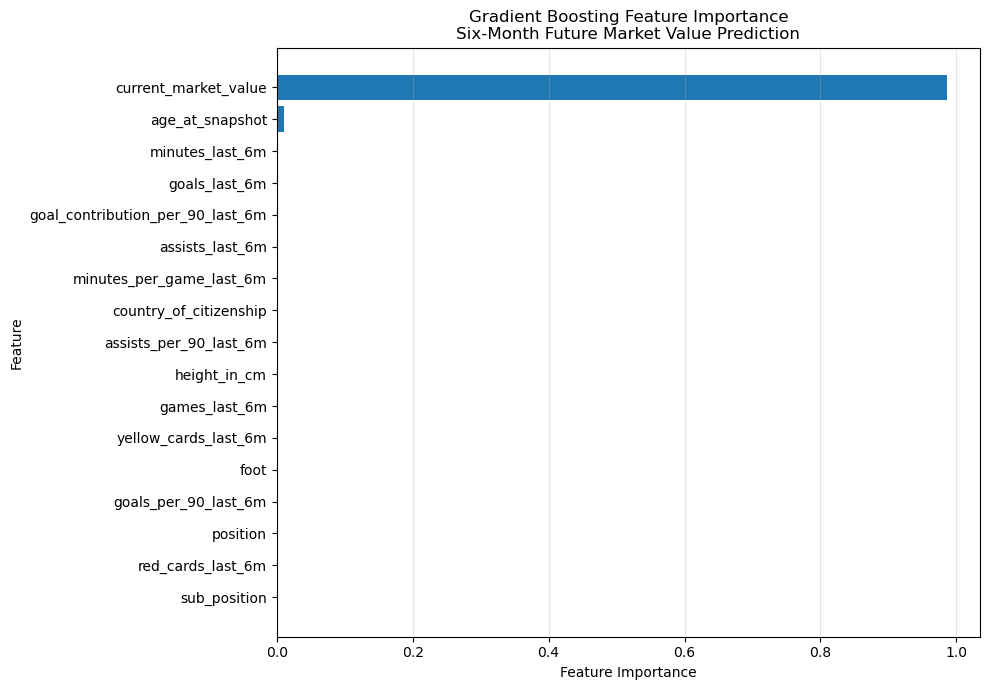

In [15]:
# ============================================================
# Gradient Boosting - Feature Importance
# ============================================================

# Get the fitted preprocessor from the Gradient Boosting pipeline
fitted_preprocessor = gradient_boosting_model.named_steps['preprocessor']

# Get transformed feature names
transformed_feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

# Get feature importance values from Gradient Boosting
importance_values = (
    gradient_boosting_model
    .named_steps['regressor']
    .feature_importances_
)

# Create raw transformed importance table
raw_importance = pd.DataFrame({
    'Transformed_Feature': transformed_feature_names,
    'Importance': importance_values
})

# ------------------------------------------------------------
# Map transformed columns back to the original 17 features
# ------------------------------------------------------------

def get_original_feature(transformed_name):

    # Remove ColumnTransformer prefixes
    name = transformed_name.split('__', 1)[-1]

    # Numeric features remain unchanged
    if name in NUMERIC_FEATURES:
        return name

    # One-hot encoded categorical features
    for feature in CATEGORICAL_FEATURES:
        if name.startswith(feature + '_'):
            return feature

    return name


raw_importance['Feature'] = (
    raw_importance['Transformed_Feature']
    .apply(get_original_feature)
)

# Aggregate one-hot encoded categories back to original features
feature_importance = (
    raw_importance
    .groupby('Feature', as_index=False)['Importance']
    .sum()
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

print("=" * 70)
print("GRADIENT BOOSTING - FEATURE IMPORTANCE")
print("=" * 70)

print(f"\nOriginal predictive features : {len(FEATURES)}")
print(f"Transformed model features   : {len(transformed_feature_names)}")

print("\nAggregated feature importance:")
display(feature_importance)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance['Feature'][::-1],
    feature_importance['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.title(
    'Gradient Boosting Feature Importance\n'
    'Six-Month Future Market Value Prediction'
)

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# Detailed Feature Importance
# ============================================================

feature_importance_detailed = feature_importance.copy()

feature_importance_detailed['Importance_Percent'] = (
    feature_importance_detailed['Importance'] * 100
)

print("=" * 70)
print("DETAILED FEATURE IMPORTANCE")
print("=" * 70)

display(
    feature_importance_detailed.style.format({
        'Importance': '{:.6f}',
        'Importance_Percent': '{:.4f}%'
    })
)

print(
    "\nTotal importance:",
    round(feature_importance['Importance'].sum(), 6)
)

DETAILED FEATURE IMPORTANCE


,Feature,Importance,Importance_Percent
0,current_market_value,0.985463,98.5463%
1,age_at_snapshot,0.010526,1.0526%
2,minutes_last_6m,0.001410,0.1410%
3,goals_last_6m,0.001199,0.1199%
4,goal_contribution_per_90_last_6m,0.000491,0.0491%
5,assists_last_6m,0.000344,0.0344%
6,minutes_per_game_last_6m,0.000271,0.0271%
7,country_of_citizenship,0.000183,0.0183%
8,assists_per_90_last_6m,0.000064,0.0064%
9,height_in_cm,0.000031,0.0031%



Total importance: 1.0


In [17]:
# ============================================================
# Ablation Experiment - Without Current Market Value
# ============================================================

# ------------------------------------------------------------
# 1. Create feature lists without current_market_value
# ------------------------------------------------------------

ABLATION_NUMERIC_FEATURES = [
    feature
    for feature in NUMERIC_FEATURES
    if feature != 'current_market_value'
]

ABLATION_FEATURES = (
    ABLATION_NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)


# ------------------------------------------------------------
# 2. Create ablation training and validation data
# ------------------------------------------------------------

X_train_ablation = train_df[ABLATION_FEATURES]
X_validation_ablation = validation_df[ABLATION_FEATURES]


# ------------------------------------------------------------
# 3. Create preprocessing pipeline
# ------------------------------------------------------------

ablation_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

ablation_categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

ablation_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            ablation_numeric_pipeline,
            ABLATION_NUMERIC_FEATURES
        ),
        (
            'categorical',
            ablation_categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ]
)


# ------------------------------------------------------------
# 4. Create Gradient Boosting model
# ------------------------------------------------------------

ablation_gb_model = Pipeline(steps=[
    ('preprocessor', ablation_preprocessor),

    ('regressor', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])


# ------------------------------------------------------------
# 5. Train using TRAINING data only
# ------------------------------------------------------------

ablation_gb_model.fit(
    X_train_ablation,
    y_train
)


# ------------------------------------------------------------
# 6. Predict validation data
# ------------------------------------------------------------

y_val_pred_ablation = ablation_gb_model.predict(
    X_validation_ablation
)


# ------------------------------------------------------------
# 7. Evaluate
# ------------------------------------------------------------

ablation_r2 = r2_score(
    y_validation,
    y_val_pred_ablation
)

ablation_mae = mean_absolute_error(
    y_validation,
    y_val_pred_ablation
)

ablation_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_val_pred_ablation
    )
)


# ------------------------------------------------------------
# 8. Display comparison
# ------------------------------------------------------------

print("=" * 70)
print("ABLATION EXPERIMENT - WITHOUT CURRENT MARKET VALUE")
print("=" * 70)

print(f"\nFeatures used : {len(ABLATION_FEATURES)}")

print("\nWithout current_market_value:")
print(f"R²   : {ablation_r2:.4f}")
print(f"MAE  : €{ablation_mae:,.0f}")
print(f"RMSE : €{ablation_rmse:,.0f}")

print("\nFull 17-feature Gradient Boosting:")
print(f"R²   : {gb_val_r2:.4f}")
print(f"MAE  : €{gb_val_mae:,.0f}")
print(f"RMSE : €{gb_val_rmse:,.0f}")

ABLATION EXPERIMENT - WITHOUT CURRENT MARKET VALUE

Features used : 16

Without current_market_value:
R²   : 0.3953
MAE  : €4,249,305
RMSE : €9,751,137

Full 17-feature Gradient Boosting:
R²   : 0.9398
MAE  : €1,187,352
RMSE : €3,075,869


In [18]:
# ============================================================
# Reduced Feature Experiment
# ============================================================

# ------------------------------------------------------------
# 1. Define controlled feature sets
# ------------------------------------------------------------

REDUCED_FEATURE_SETS = {

    'Top 2': [
        'current_market_value',
        'age_at_snapshot'
    ],

    'Top 4': [
        'current_market_value',
        'age_at_snapshot',
        'minutes_last_6m',
        'goals_last_6m'
    ],

    'Top 7': [
        'current_market_value',
        'age_at_snapshot',
        'minutes_last_6m',
        'goals_last_6m',
        'goal_contribution_per_90_last_6m',
        'assists_last_6m',
        'minutes_per_game_last_6m'
    ]
}


# ------------------------------------------------------------
# 2. Train and evaluate each reduced model
# ------------------------------------------------------------

reduced_results = []

for set_name, selected_features in REDUCED_FEATURE_SETS.items():

    # All selected features are numeric
    X_train_reduced = train_df[selected_features]
    X_validation_reduced = validation_df[selected_features]

    # Numeric preprocessing
    reduced_preprocessor = ColumnTransformer(
        transformers=[
            (
                'numeric',
                Pipeline(steps=[
                    (
                        'imputer',
                        SimpleImputer(strategy='median')
                    )
                ]),
                selected_features
            )
        ]
    )

    # Same Gradient Boosting configuration
    reduced_model = Pipeline(steps=[
        (
            'preprocessor',
            reduced_preprocessor
        ),
        (
            'regressor',
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ])

    # Train
    reduced_model.fit(
        X_train_reduced,
        y_train
    )

    # Validation prediction
    y_val_pred_reduced = reduced_model.predict(
        X_validation_reduced
    )

    # Metrics
    reduced_r2 = r2_score(
        y_validation,
        y_val_pred_reduced
    )

    reduced_mae = mean_absolute_error(
        y_validation,
        y_val_pred_reduced
    )

    reduced_rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            y_val_pred_reduced
        )
    )

    reduced_results.append({
        'Feature_Set': set_name,
        'N_Features': len(selected_features),
        'R2': reduced_r2,
        'MAE_EUR': reduced_mae,
        'RMSE_EUR': reduced_rmse
    })


# ------------------------------------------------------------
# 3. Add the full 17-feature model
# ------------------------------------------------------------

reduced_results.append({
    'Feature_Set': 'Full 17',
    'N_Features': 17,
    'R2': gb_val_r2,
    'MAE_EUR': gb_val_mae,
    'RMSE_EUR': gb_val_rmse
})


# ------------------------------------------------------------
# 4. Create comparison table
# ------------------------------------------------------------

reduced_feature_results = pd.DataFrame(
    reduced_results
)

print("=" * 75)
print("REDUCED FEATURE EXPERIMENT - VALIDATION")
print("=" * 75)

display(
    reduced_feature_results.style.format({
        'R2': '{:.4f}',
        'MAE_EUR': '€{:,.0f}',
        'RMSE_EUR': '€{:,.0f}'
    })
)

REDUCED FEATURE EXPERIMENT - VALIDATION


,Feature_Set,N_Features,R2,MAE_EUR,RMSE_EUR
0,Top 2,2,0.9386,"€1,193,032","€3,106,168"
1,Top 4,4,0.9401,"€1,190,701","€3,068,609"
2,Top 7,7,0.9397,"€1,188,753","€3,079,508"
3,Full 17,17,0.9398,"€1,187,352","€3,075,869"


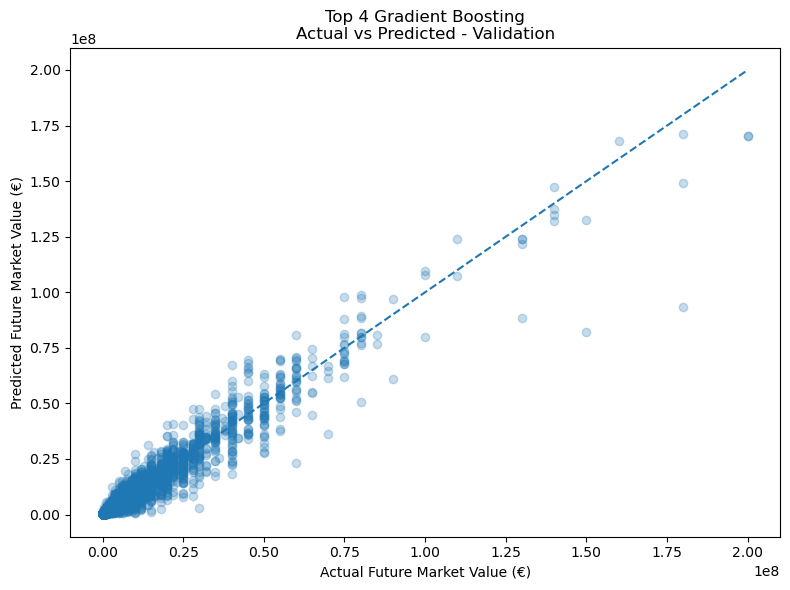

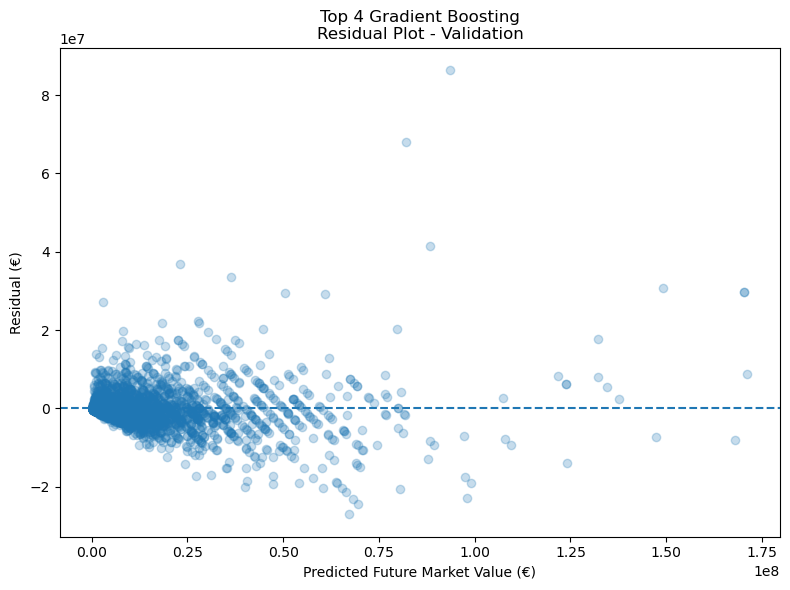

TOP 4 MODEL - VALIDATION RESIDUAL SUMMARY

Mean residual   : €-93,474
Median residual : €-99,987

Minimum residual: €-27,120,472
Maximum residual: €86,428,722



In [19]:
# ============================================================
# Top 4 Candidate Model - Validation Diagnostics
# ============================================================

TOP4_FEATURES = [
    'current_market_value',
    'age_at_snapshot',
    'minutes_last_6m',
    'goals_last_6m'
]

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

X_train_top4 = train_df[TOP4_FEATURES]
X_validation_top4 = validation_df[TOP4_FEATURES]


# ------------------------------------------------------------
# 2. Preprocessing
# ------------------------------------------------------------

top4_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='median'))
            ]),
            TOP4_FEATURES
        )
    ]
)


# ------------------------------------------------------------
# 3. Train the Top 4 candidate model
# ------------------------------------------------------------

top4_model = Pipeline(steps=[
    ('preprocessor', top4_preprocessor),

    ('regressor', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

top4_model.fit(
    X_train_top4,
    y_train
)


# ------------------------------------------------------------
# 4. Validation prediction
# ------------------------------------------------------------

y_val_pred_top4 = top4_model.predict(
    X_validation_top4
)


# ------------------------------------------------------------
# 5. Residuals
# residual = actual - predicted
# ------------------------------------------------------------

val_residuals_top4 = (
    y_validation - y_val_pred_top4
)


# ------------------------------------------------------------
# 6. Actual vs Predicted
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_validation,
    y_val_pred_top4,
    alpha=0.25
)

min_value = min(
    y_validation.min(),
    y_val_pred_top4.min()
)

max_value = max(
    y_validation.max(),
    y_val_pred_top4.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Future Market Value (€)')
plt.ylabel('Predicted Future Market Value (€)')

plt.title(
    'Top 4 Gradient Boosting\n'
    'Actual vs Predicted - Validation'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Residual Plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_pred_top4,
    val_residuals_top4,
    alpha=0.25
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Future Market Value (€)')
plt.ylabel('Residual (€)')

plt.title(
    'Top 4 Gradient Boosting\n'
    'Residual Plot - Validation'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Residual summary
# ------------------------------------------------------------

print("=" * 70)
print("TOP 4 MODEL - VALIDATION RESIDUAL SUMMARY")
print("=" * 70)

print(f"""
Mean residual   : €{val_residuals_top4.mean():,.0f}
Median residual : €{val_residuals_top4.median():,.0f}

Minimum residual: €{val_residuals_top4.min():,.0f}
Maximum residual: €{val_residuals_top4.max():,.0f}
""")

In [20]:
# ============================================================
# Final Model - Test Evaluation
# ============================================================

# ------------------------------------------------------------
# 1. Prepare untouched test data
# ------------------------------------------------------------

X_test_top4 = test_df[TOP4_FEATURES]


# ------------------------------------------------------------
# 2. Predict the test set using the selected Top 4 model
# ------------------------------------------------------------

y_test_pred_top4 = top4_model.predict(
    X_test_top4
)


# ------------------------------------------------------------
# 3. Calculate final test metrics
# ------------------------------------------------------------

top4_test_r2 = r2_score(
    y_test,
    y_test_pred_top4
)

top4_test_mae = mean_absolute_error(
    y_test,
    y_test_pred_top4
)

top4_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_top4
    )
)


# ------------------------------------------------------------
# 4. Persistence baseline on the same test set
# ------------------------------------------------------------

y_test_pred_persistence = (
    test_df['current_market_value']
)

persistence_test_r2 = r2_score(
    y_test,
    y_test_pred_persistence
)

persistence_test_mae = mean_absolute_error(
    y_test,
    y_test_pred_persistence
)

persistence_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_persistence
    )
)


# ------------------------------------------------------------
# 5. Display final test comparison
# ------------------------------------------------------------

final_test_results = pd.DataFrame({
    'Model': [
        'Persistence Baseline',
        'Top 4 Gradient Boosting'
    ],

    'R2': [
        persistence_test_r2,
        top4_test_r2
    ],

    'MAE_EUR': [
        persistence_test_mae,
        top4_test_mae
    ],

    'RMSE_EUR': [
        persistence_test_rmse,
        top4_test_rmse
    ]
})


print("=" * 75)
print("FINAL TEST EVALUATION")
print("=" * 75)

print("\nSelected final features:")
for feature in TOP4_FEATURES:
    print(f" - {feature}")

print(f"\nTest rows: {len(X_test_top4):,}")

display(
    final_test_results.style.format({
        'R2': '{:.4f}',
        'MAE_EUR': '€{:,.0f}',
        'RMSE_EUR': '€{:,.0f}'
    })
)

FINAL TEST EVALUATION

Selected final features:
 - current_market_value
 - age_at_snapshot
 - minutes_last_6m
 - goals_last_6m

Test rows: 10,892


,Model,R2,MAE_EUR,RMSE_EUR
0,Persistence Baseline,0.9040,"€1,473,426","€3,848,526"
1,Top 4 Gradient Boosting,0.9175,"€1,423,911","€3,566,904"


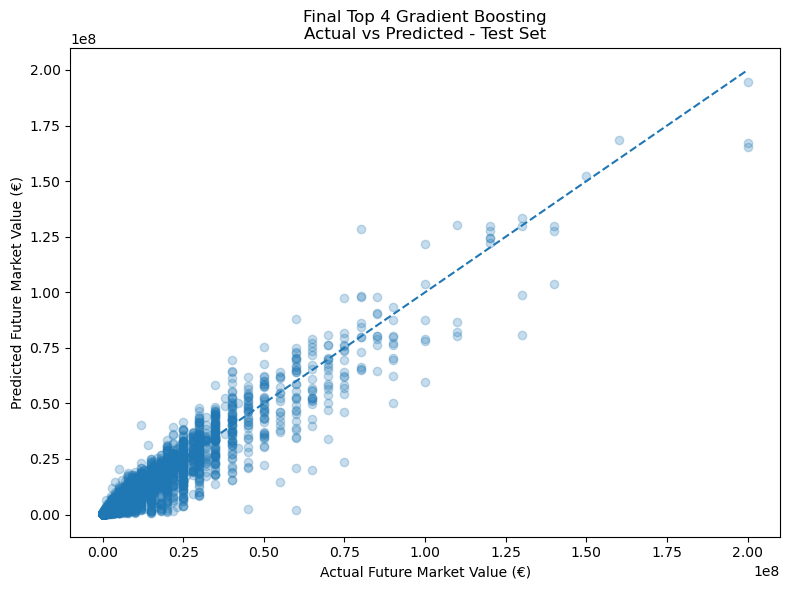

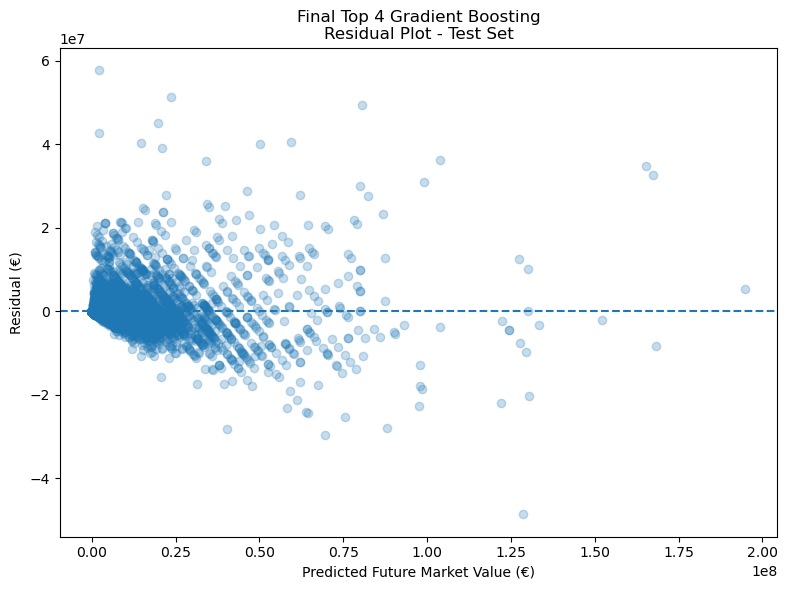

FINAL TOP 4 MODEL - TEST RESIDUAL SUMMARY

Mean residual    : €118,446
Median residual  : €-96,246

Minimum residual : €-48,624,807
Maximum residual : €57,782,337

FINAL TEST PERFORMANCE
----------------------------------------------------------------------
R²   : 0.9175
MAE  : €1,423,911
RMSE : €3,566,904


In [21]:
# ============================================================
# Final Model - Test Diagnostics
# ============================================================

# ------------------------------------------------------------
# 1. Calculate test residuals
# residual = actual - predicted
# ------------------------------------------------------------

test_residuals_top4 = (
    y_test - y_test_pred_top4
)


# ------------------------------------------------------------
# 2. Actual vs Predicted - Test Set
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_top4,
    alpha=0.25
)

min_value = min(
    y_test.min(),
    y_test_pred_top4.min()
)

max_value = max(
    y_test.max(),
    y_test_pred_top4.max()
)

# Perfect prediction line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Future Market Value (€)')
plt.ylabel('Predicted Future Market Value (€)')

plt.title(
    'Final Top 4 Gradient Boosting\n'
    'Actual vs Predicted - Test Set'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Residual Plot - Test Set
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_top4,
    test_residuals_top4,
    alpha=0.25
)

# Zero-error reference line
plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Future Market Value (€)')
plt.ylabel('Residual (€)')

plt.title(
    'Final Top 4 Gradient Boosting\n'
    'Residual Plot - Test Set'
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Test residual summary
# ------------------------------------------------------------

print("=" * 70)
print("FINAL TOP 4 MODEL - TEST RESIDUAL SUMMARY")
print("=" * 70)

print(f"""
Mean residual    : €{test_residuals_top4.mean():,.0f}
Median residual  : €{test_residuals_top4.median():,.0f}

Minimum residual : €{test_residuals_top4.min():,.0f}
Maximum residual : €{test_residuals_top4.max():,.0f}
""")


# ------------------------------------------------------------
# 5. Final test metrics
# ------------------------------------------------------------

print("FINAL TEST PERFORMANCE")
print("-" * 70)

print(f"R²   : {top4_test_r2:.4f}")
print(f"MAE  : €{top4_test_mae:,.0f}")
print(f"RMSE : €{top4_test_rmse:,.0f}")

In [22]:
# ============================================================
# Save Final Experiment 2 Model
# ============================================================

from pathlib import Path
import joblib
import json


# ------------------------------------------------------------
# 1. Create model output directory
# ------------------------------------------------------------

MODEL_DIR = Path('../../../models/experiment_2')

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Save trained Top 4 pipeline
# ------------------------------------------------------------

MODEL_PATH = (
    MODEL_DIR /
    'gradient_boosting_top4_future_value.joblib'
)

joblib.dump(
    top4_model,
    MODEL_PATH
)


# ------------------------------------------------------------
# 3. Save model metadata
# ------------------------------------------------------------

metadata = {
    'experiment': 'Experiment 2 - Future Market Value Prediction',

    'task': (
        'Predict football player market value '
        'approximately six months ahead'
    ),

    'model': 'GradientBoostingRegressor',

    'features': TOP4_FEATURES,

    'n_features': len(TOP4_FEATURES),

    'forecast_horizon': 'approximately 6 months',

    'test_metrics': {
        'r2': float(top4_test_r2),
        'mae_eur': float(top4_test_mae),
        'rmse_eur': float(top4_test_rmse)
    },

    'persistence_baseline_test': {
        'r2': float(persistence_test_r2),
        'mae_eur': float(persistence_test_mae),
        'rmse_eur': float(persistence_test_rmse)
    }
}


METADATA_PATH = (
    MODEL_DIR /
    'gradient_boosting_top4_future_value_metadata.json'
)

with open(
    METADATA_PATH,
    'w',
    encoding='utf-8'
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )


# ------------------------------------------------------------
# 4. Confirmation
# ------------------------------------------------------------

print("=" * 70)
print("FINAL EXPERIMENT 2 MODEL SAVED")
print("=" * 70)

print(f"\nModel:")
print(MODEL_PATH)

print(f"\nMetadata:")
print(METADATA_PATH)

print("\nFinal features:")
for feature in TOP4_FEATURES:
    print(f" - {feature}")

print("\nFinal test performance:")
print(f"R²   : {top4_test_r2:.4f}")
print(f"MAE  : €{top4_test_mae:,.0f}")
print(f"RMSE : €{top4_test_rmse:,.0f}")

FINAL EXPERIMENT 2 MODEL SAVED

Model:
..\..\..\models\experiment_2\gradient_boosting_top4_future_value.joblib

Metadata:
..\..\..\models\experiment_2\gradient_boosting_top4_future_value_metadata.json

Final features:
 - current_market_value
 - age_at_snapshot
 - minutes_last_6m
 - goals_last_6m

Final test performance:
R²   : 0.9175
MAE  : €1,423,911
RMSE : €3,566,904


In [23]:
# ============================================================
# Experiment 2 - Final Summary
# ============================================================

# ------------------------------------------------------------
# Improvement over persistence baseline on final test set
# ------------------------------------------------------------

final_r2_improvement = (
    top4_test_r2 - persistence_test_r2
)

final_mae_reduction = (
    persistence_test_mae - top4_test_mae
)

final_rmse_reduction = (
    persistence_test_rmse - top4_test_rmse
)

final_mae_reduction_pct = (
    final_mae_reduction / persistence_test_mae
) * 100

final_rmse_reduction_pct = (
    final_rmse_reduction / persistence_test_rmse
) * 100


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("=" * 75)
print("EXPERIMENT 2 — FINAL SUMMARY")
print("=" * 75)

print(f"""
Task:
  Six-Month-Ahead Football Market Value Prediction

Learning Method:
  Supervised Regression

Temporal Design:
  Historical player snapshots → future market value
  approximately six months later

Dataset:
  Total snapshots : {len(df):,}
  Train rows      : {len(train_df):,}
  Validation rows : {len(validation_df):,}
  Test rows       : {len(test_df):,}

Final Model:
  Algorithm       : Gradient Boosting Regressor
  Features        : {len(TOP4_FEATURES)}

Selected Features:
  1. current_market_value
  2. age_at_snapshot
  3. minutes_last_6m
  4. goals_last_6m

Validation Performance:
  R²              : 0.9401
  MAE             : €1,190,701
  RMSE            : €3,068,609

Final Test Performance:
  R²              : {top4_test_r2:.4f}
  MAE             : €{top4_test_mae:,.0f}
  RMSE            : €{top4_test_rmse:,.0f}

Persistence Baseline — Test:
  R²              : {persistence_test_r2:.4f}
  MAE             : €{persistence_test_mae:,.0f}
  RMSE            : €{persistence_test_rmse:,.0f}

Improvement Over Persistence — Test:
  R² increase     : {final_r2_improvement:+.4f}
  MAE reduction   : €{final_mae_reduction:,.0f}
  MAE reduction % : {final_mae_reduction_pct:.2f}%
  RMSE reduction  : €{final_rmse_reduction:,.0f}
  RMSE reduction %: {final_rmse_reduction_pct:.2f}%

Feature Reduction:
  Initial features: 17
  Final features  : 4
  Features removed: 13

Key Finding:
  Current market value was the dominant predictor of future
  market value. However, the selected Gradient Boosting model
  improved upon the strong persistence baseline on the unseen
  temporal test set.

Final Conclusion:
  The four-feature Gradient Boosting model provides a compact
  six-month-ahead forecasting model while maintaining strong
  predictive performance on unseen future-period data.
""")

EXPERIMENT 2 — FINAL SUMMARY

Task:
  Six-Month-Ahead Football Market Value Prediction

Learning Method:
  Supervised Regression

Temporal Design:
  Historical player snapshots → future market value
  approximately six months later

Dataset:
  Total snapshots : 213,905
  Train rows      : 174,997
  Validation rows : 8,200
  Test rows       : 10,892

Final Model:
  Algorithm       : Gradient Boosting Regressor
  Features        : 4

Selected Features:
  1. current_market_value
  2. age_at_snapshot
  3. minutes_last_6m
  4. goals_last_6m

Validation Performance:
  R²              : 0.9401
  MAE             : €1,190,701
  RMSE            : €3,068,609

Final Test Performance:
  R²              : 0.9175
  MAE             : €1,423,911
  RMSE            : €3,566,904

Persistence Baseline — Test:
  R²              : 0.9040
  MAE             : €1,473,426
  RMSE            : €3,848,526

Improvement Over Persistence — Test:
  R² increase     : +0.0135
  MAE reduction   : €49,515
  MAE reduction %